In [2]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
import numpy as np
neuron.load_mechanisms('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod')
h.load_file("stdrun.hoc")
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/conn'

In [3]:
def create_comps():
    basal = h.Section(name='basal')
    basal.L = 255
    basal.diam = 8.5
    basal.Ra = 100
    basal.cm = 1
    basal.insert('pas')
    
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    return basal, soma, stim

In [4]:
def create_comps_basal_clamp(bamp=2, bdur=11):
    basal = h.Section(name='basal')
    basal.L = 255
    basal.diam = 8.5
    basal.Ra = 100
    basal.cm = 1
    basal.insert('pas')
    basal.insert('CaDynamics_E2')
    basal.insert('Ca_HVA')

    stimb = h.IClamp(basal(0.5))
    stimb.delay = 10
    stimb.dur = bdur   
    stimb.amp = bamp
    
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    return basal, soma, stim, stimb

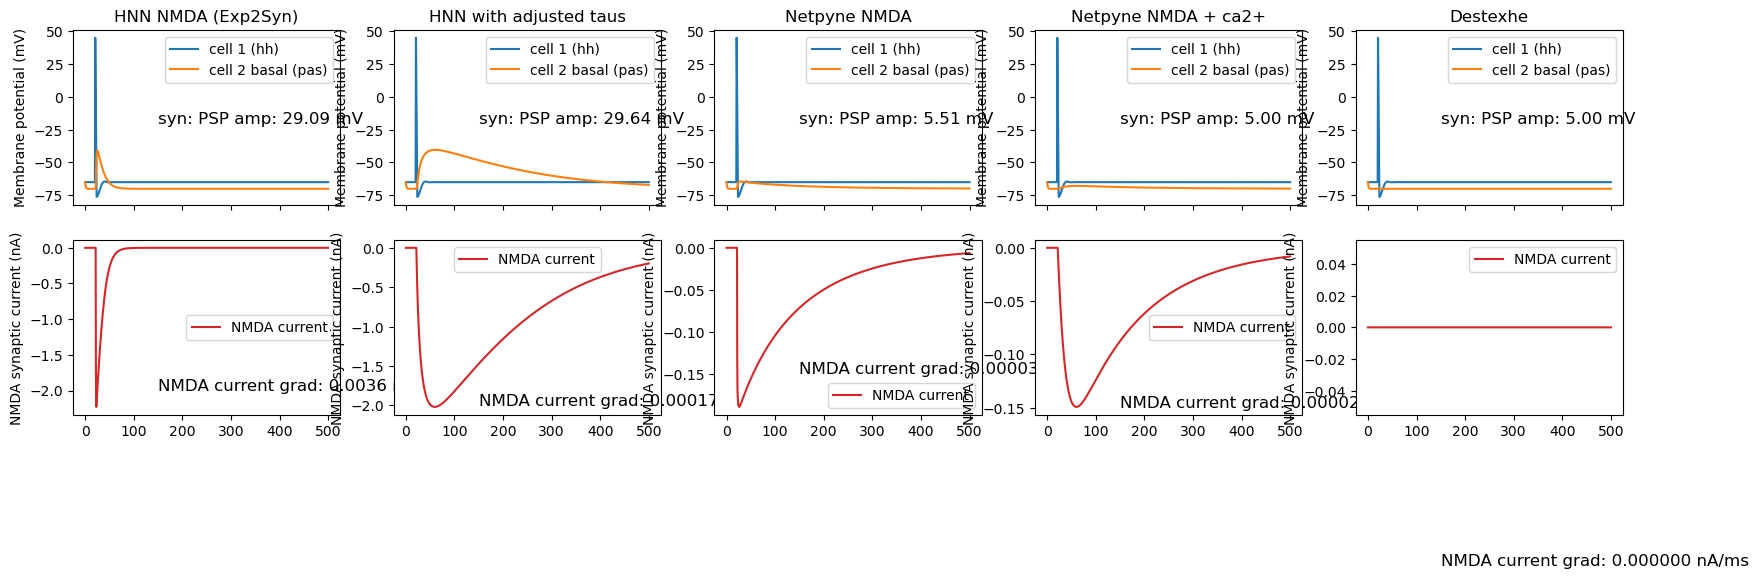

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(20, 5), sharex=True)

basal, soma, stim = create_comps()
syn = h.Exp2Syn(basal(0.5))
syn.tau1 = 1
syn.tau2 = 10
syn.e = 0

nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(soma(0.5)._ref_v)
v_basal = h.Vector().record(basal(0.5)._ref_v)
nmda_curr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)

ax[0,0].set_title('HNN NMDA (Exp2Syn)')

ax[0,0].plot(t, v_soma, label='cell 1 (hh)')
ax[0,0].plot(t, v_basal, label='cell 2 basal (pas)')
ax[0,0].set_ylabel('Membrane potential (mV)')
psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
ax[0,0].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
ax[0,0].legend()
ax[1,0].plot(t, nmda_curr, color='C3', label='NMDA current')
ax[1,0].legend()
ax[1,0].set_ylabel('NMDA synaptic current (nA)')
nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)


# Exp2Syn with adjusted taus
h('forall delete_section()')
del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


basal, soma, stim = create_comps()
syn = h.Exp2Syn(basal(0.5))
syn.tau1 = 15
syn.tau2 = 150
syn.e = 0

nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(soma(0.5)._ref_v)
v_basal = h.Vector().record(basal(0.5)._ref_v)
nmda_curr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)

ax[0,1].set_title('HNN with adjusted taus')
ax[0,1].plot(t, v_soma, label='cell 1 (hh)')
ax[0,1].plot(t, v_basal, label='cell 2 basal (pas)')
psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
ax[0,1].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
ax[0,1].set_ylabel('Membrane potential (mV)')
ax[0,1].legend()
ax[1,1].plot(t, nmda_curr, color='C3', label='NMDA current')
ax[1,1].legend()
ax[1,1].set_ylabel('NMDA synaptic current (nA)')
nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
ax[1,1].text(150, -2, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)



# Exp2Syn with adjusted taus
h('forall delete_section()')
del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
basal, soma, stim = create_comps()

syn = h.NMDA(basal(0.5))
syn.tau1 = 15
syn.tau2 = 150
syn.e = 0

nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(soma(0.5)._ref_v)
v_basal = h.Vector().record(basal(0.5)._ref_v)
nmda_curr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)

ax[0,2].set_title('Netpyne NMDA')
ax[0,2].plot(t, v_soma, label='cell 1 (hh)')
ax[0,2].plot(t, v_basal, label='cell 2 basal (pas)')
psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
ax[0,2].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
ax[0,2].set_ylabel('Membrane potential (mV)')
ax[0,2].legend()
ax[1,2].plot(t, nmda_curr, color='C3', label='NMDA current')
ax[1,2].legend()
ax[1,2].set_ylabel('NMDA synaptic current (nA)')
nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
ax[1,2].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

h('forall delete_section()')
del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


basal, soma, stim = create_comps()
syn = h.MyExp2SynNMDABB(basal(0.5))
syn.tau1 = 15
syn.tau2 = 150
syn.e = 0

nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(soma(0.5)._ref_v)
v_basal = h.Vector().record(basal(0.5)._ref_v)
nmda_curr = h.Vector().record(syn._ref_iNMDA)
h.finitialize(-65)
h.continuerun(500)

ax[0,3].set_title('Netpyne NMDA + ca2+')
ax[0,3].plot(t, v_soma, label='cell 1 (hh)')
ax[0,3].plot(t, v_basal, label='cell 2 basal (pas)')
psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
ax[0,3].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
ax[0,3].set_ylabel('Membrane potential (mV)')
ax[0,3].legend()
ax[1,3].plot(t, nmda_curr, color='C3', label='NMDA current')
ax[1,3].legend()
ax[1,3].set_ylabel('NMDA synaptic current (nA)')
nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
ax[1,3].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

h('forall delete_section()')
del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


basal, soma, stim = create_comps()
syn = h.nmda_des(basal(0.5))
syn.tau1 = 15
syn.tau2 = 150
syn.e = 0

nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(soma(0.5)._ref_v)
v_basal = h.Vector().record(basal(0.5)._ref_v)
nmda_curr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)

ax[0,4].set_title('Destexhe')
ax[0,4].plot(t, v_soma, label='cell 1 (hh)')
ax[0,4].plot(t, v_basal, label='cell 2 basal (pas)')
psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
ax[0,4].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
ax[0,4].set_ylabel('Membrane potential (mV)')
ax[0,4].legend()
ax[1,4].plot(t, nmda_curr, color='C3', label='NMDA current')
ax[1,4].legend()
ax[1,4].set_ylabel('NMDA synaptic current (nA)')
nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
ax[1,4].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

fig.savefig(f'{pathfig}/NMDA_comparison_single_syn.png')

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_2705/3754516645.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1,0].legend()
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_2705/3754516645.py:87: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1,1].legend()


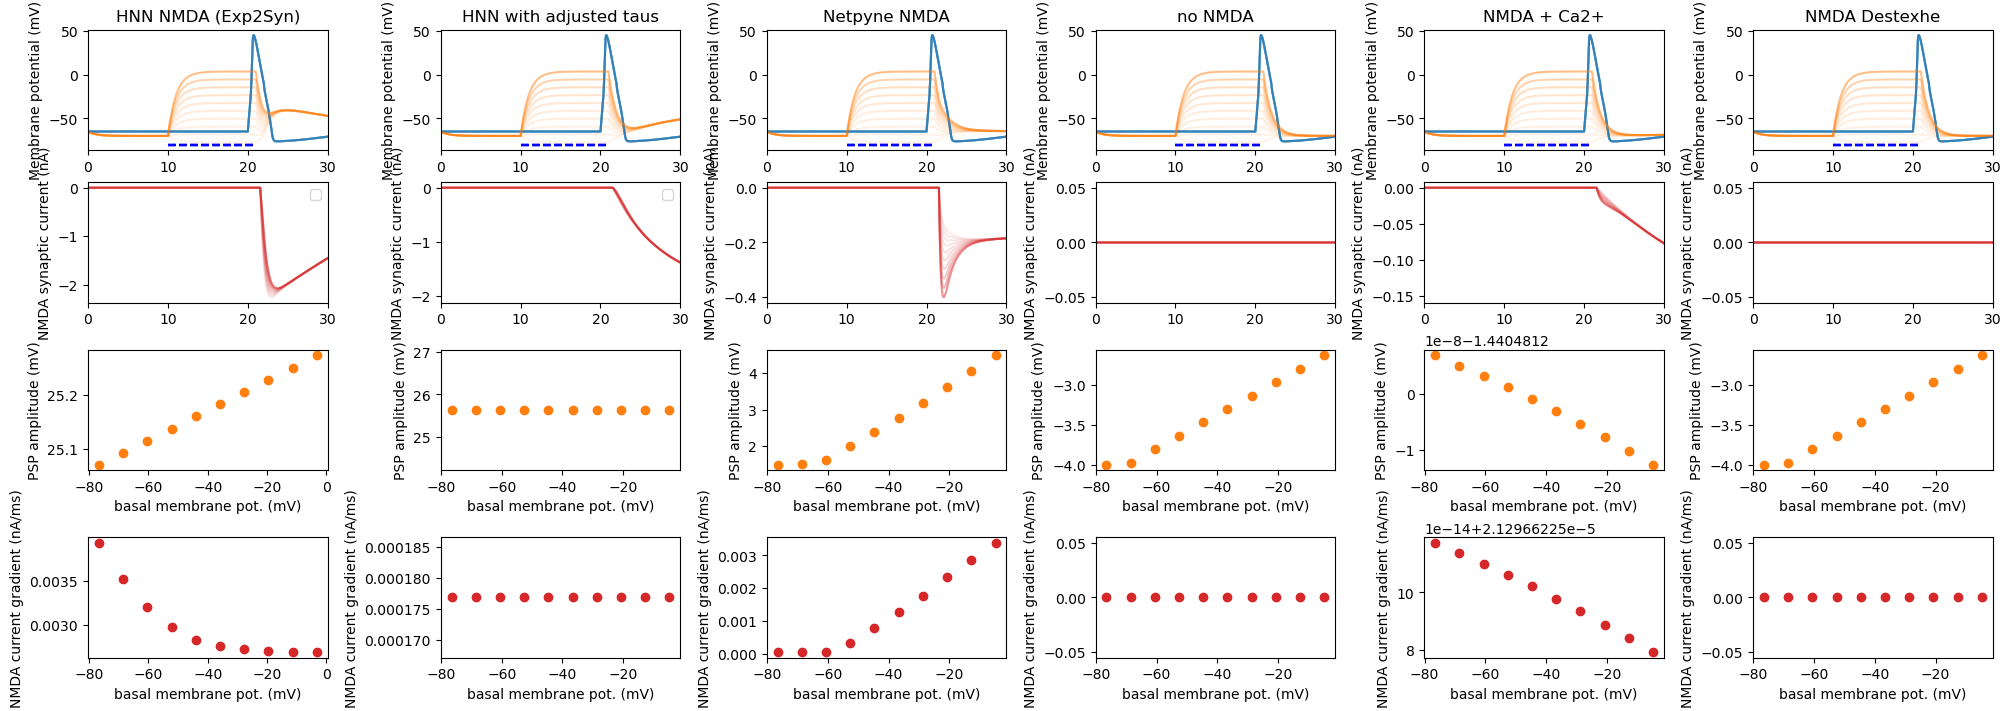

In [16]:
fig, ax = plt.subplots(4, 6, figsize=(20, 7), constrained_layout=True)

bamps = np.linspace(-0.5, 5, 10)
for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 1
    syn.tau2 = 10
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,0].set_title('HNN NMDA (Exp2Syn)')

    ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,0].set_ylabel('Membrane potential (mV)')
    ax[0,0].set_xlim(0, 30)
    ax[0,0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    t1 = 10
    t2 = 21
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,0].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,0].set_xlabel('basal membrane pot. (mV)')
    ax[2,0].set_ylabel('PSP amplitude (mV)')
 
    ax[1,0].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,0].legend()
    ax[1,0].set_ylabel('NMDA synaptic current (nA)')
    ax[1,0].set_xlim(0, 30)
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,0].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,0].set_xlabel('basal membrane pot. (mV)')
    ax[3,0].set_ylabel('NMDA current gradient (nA/ms)')
    # ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)

for b, bamp in enumerate(bamps):
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,1].set_title('HNN with adjusted taus')

    ax[0,1].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    ax[0,1].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,1].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,1].set_ylabel('Membrane potential (mV)')
    ax[0,1].set_xlim(0, 30)
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,1].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,1].set_xlabel('basal membrane pot. (mV)')
    ax[2,1].set_ylabel('PSP amplitude (mV)')
 
    ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,1].legend()
    ax[1,1].set_ylabel('NMDA synaptic current (nA)')
    ax[1,1].set_xlim(0, 30)
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,1].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,1].set_xlabel('basal membrane pot. (mV)')
    ax[3,1].set_ylabel('NMDA current gradient (nA/ms)')

for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,2].set_title('Netpyne NMDA')

    ax[0,2].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,2].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,2].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,2].set_xlim(0, 30)
    ax[0,2].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,2].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,2].set_xlabel('basal membrane pot. (mV)')
    ax[2,2].set_ylabel('PSP amplitude (mV)')
 
    ax[1,2].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,2].set_ylabel('NMDA synaptic current (nA)')
    ax[1,2].set_xlim(0, 30)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,2].set_xlabel('basal membrane pot. (mV)')
    ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    # nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    # nc.weight[0] = 0.05
    # nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,3].set_title('no NMDA')

    ax[0,3].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,3].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,3].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,3].set_xlim(0, 30)
    ax[0,3].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,3].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,3].set_xlabel('basal membrane pot. (mV)')
    ax[2,3].set_ylabel('PSP amplitude (mV)')
 
    ax[1,3].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,3].set_ylabel('NMDA synaptic current (nA)')
    ax[1,3].set_xlim(0, 30)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,3].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,3].set_xlabel('basal membrane pot. (mV)')
    ax[3,3].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_cai)

    h.finitialize(-65)
    h.continuerun(500)

    ax[0,4].set_title('NMDA + Ca2+')

    ax[0,4].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,4].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,4].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,4].set_xlim(0, 30)
    ax[0,4].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,4].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,4].set_xlabel('basal membrane pot. (mV)')
    ax[2,4].set_ylabel('PSP amplitude (mV)')
 
    ax[1,4].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,4].set_ylabel('NMDA synaptic current (nA)')
    ax[1,4].set_xlim(0, 30)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,4].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,4].set_xlabel('basal membrane pot. (mV)')
    ax[3,4].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.nmda_des(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,5].set_title('NMDA Destexhe')

    ax[0,5].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,5].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,5].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,5].set_xlim(0, 30)
    ax[0,5].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,5].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,5].set_xlabel('basal membrane pot. (mV)')
    ax[2,5].set_ylabel('PSP amplitude (mV)')
 
    ax[1,5].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,5].set_ylabel('NMDA synaptic current (nA)')
    ax[1,5].set_xlim(0, 30)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,5].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,5].set_xlabel('basal membrane pot. (mV)')
    ax[3,5].set_ylabel('NMDA current gradient (nA/ms)')

fig.savefig(f'{pathfig}/NMDA_comparison_depolarization.png')

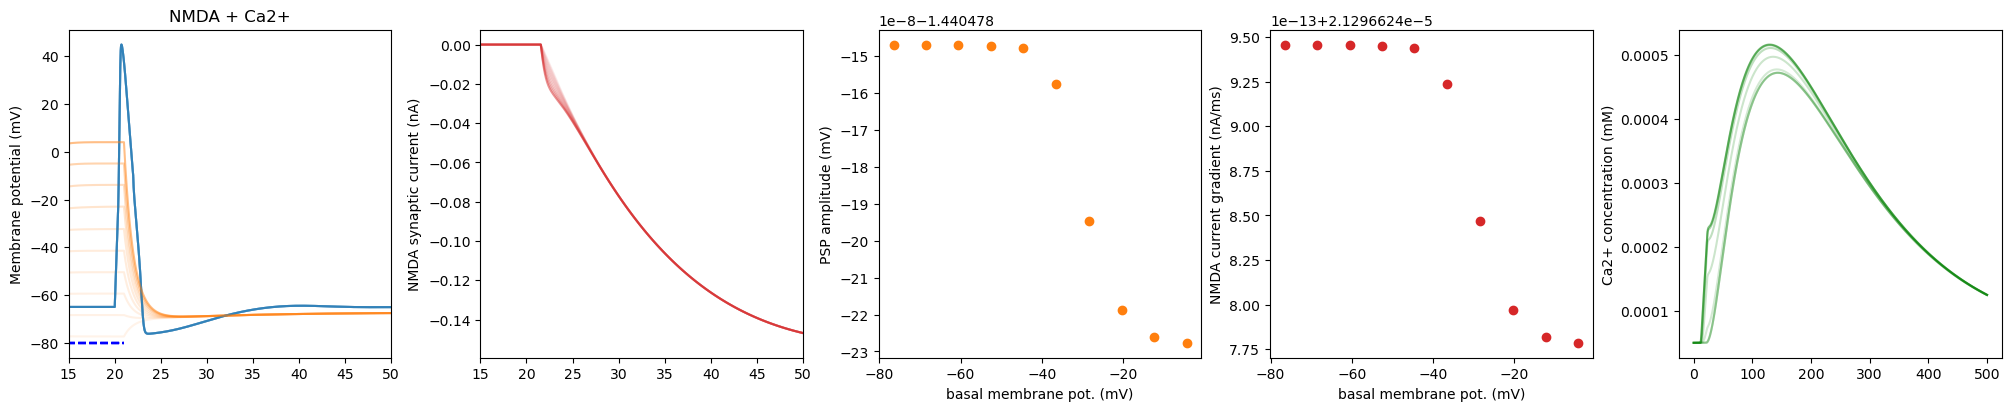

In [ ]:
# this is with the synaptic weight in Neymotin 2011
fig, ax = plt.subplots(1,5, figsize=(20,4), constrained_layout=True)
bamps = np.linspace(-0.5, 5, 10)

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[0].set_title('NMDA + Ca2+')

    ax[0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0].set_ylabel('Membrane potential (mV)')
    ax[0].set_xlim(15, 50)
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2].plot(RMP, psp, 'o', color='tab:orange')
    ax[2].set_xlabel('basal membrane pot. (mV)')
    ax[2].set_ylabel('PSP amplitude (mV)')
 
    ax[1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1].set_ylabel('NMDA synaptic current (nA)')
    ax[1].set_xlim(15, 50)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3].set_xlabel('basal membrane pot. (mV)')
    ax[3].set_ylabel('NMDA current gradient (nA/ms)')

    ax[4].plot(t, ca_curr, color='green', alpha=1/(len(bamps)+1-b))
    ax[4].set_ylabel('Ca2+ concentration (mM)')


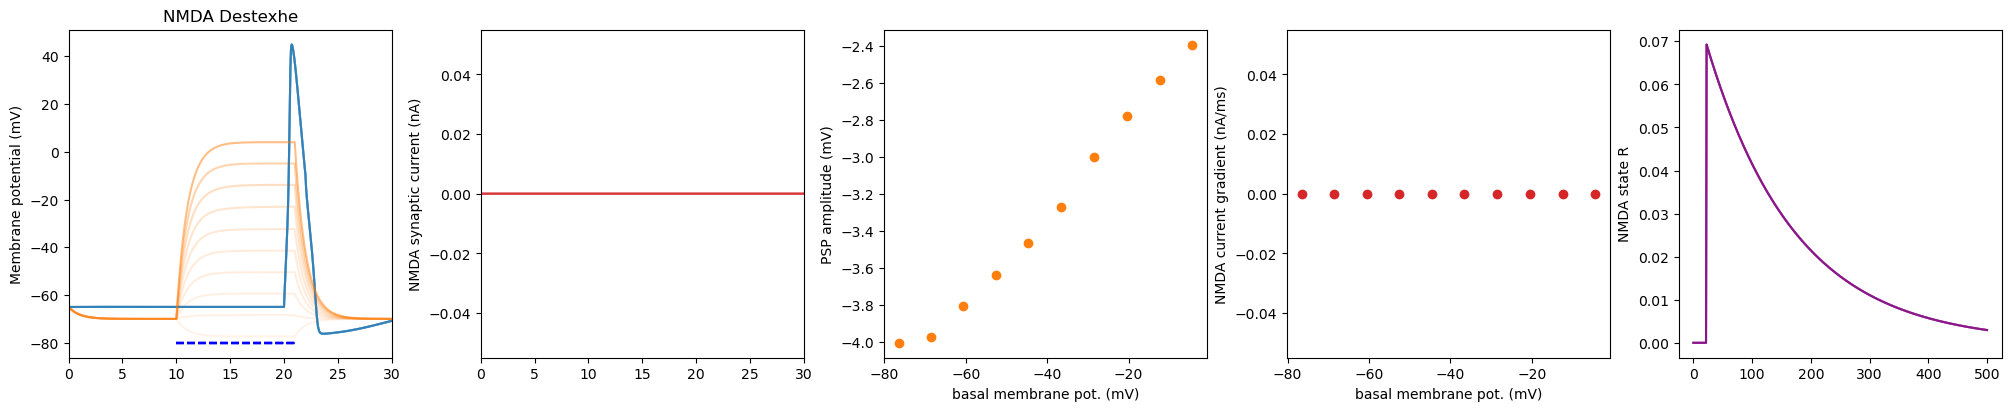

In [11]:
fig, ax = plt.subplots(1,5, figsize=(20,4), constrained_layout=True)

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.nmda_des(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    state_R = h.Vector().record(syn._ref_state_R)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0].set_title('NMDA Destexhe')

    ax[0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0].set_xlim(0, 30)
    ax[0].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2].plot(RMP, psp, 'o', color='tab:orange')
    ax[2].set_xlabel('basal membrane pot. (mV)')
    ax[2].set_ylabel('PSP amplitude (mV)')
 
    ax[1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1].set_ylabel('NMDA synaptic current (nA)')
    ax[1].set_xlim(0, 30)

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3].set_xlabel('basal membrane pot. (mV)')
    ax[3].set_ylabel('NMDA current gradient (nA/ms)')

    ax[4].plot(t, state_R, color='purple', alpha=1/(len(bamps)+1-b))
    ax[4].set_ylabel('NMDA state R')    

In [13]:
nmda_curr.as_numpy()

array([-0., -0., -0., ..., -0., -0., -0.], shape=(20001,))

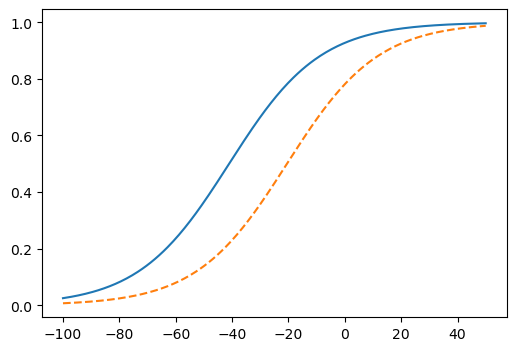

In [18]:
def mgblock(v):
    mg = 1  # extracellular Mg2+ concentration in mM
    return 1 / (1 +  0.28 * np.exp(-0.062 * v) * (mg / 3.57))

def mgblock_hoc(v):
    return 1.0 / (1.0 + 0.28 * np.exp(-0.062 * v) )

v_vals = np.linspace(-100, 50, 300)
mg_vals = mgblock(v_vals)
plt.figure(figsize=(6,4))
plt.plot(v_vals, mg_vals, label='Python function', color='C0')
mg_vals_hoc = mgblock_hoc(v_vals)
plt.plot(v_vals, mg_vals_hoc, linestyle='--', label='HOC function', color='C1')



In [ ]:
np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])

np.float64(25.71097377350941)

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_2705/3777802140.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1,0].legend()
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_2705/3777802140.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1,1].legend()


17.09463622506407
17.094635076591985
17.09463387542924
17.09463262788082
17.094631343787135
17.094630036402975
17.094628721588343
17.094627416350505
17.094626137054775
17.09462489778347


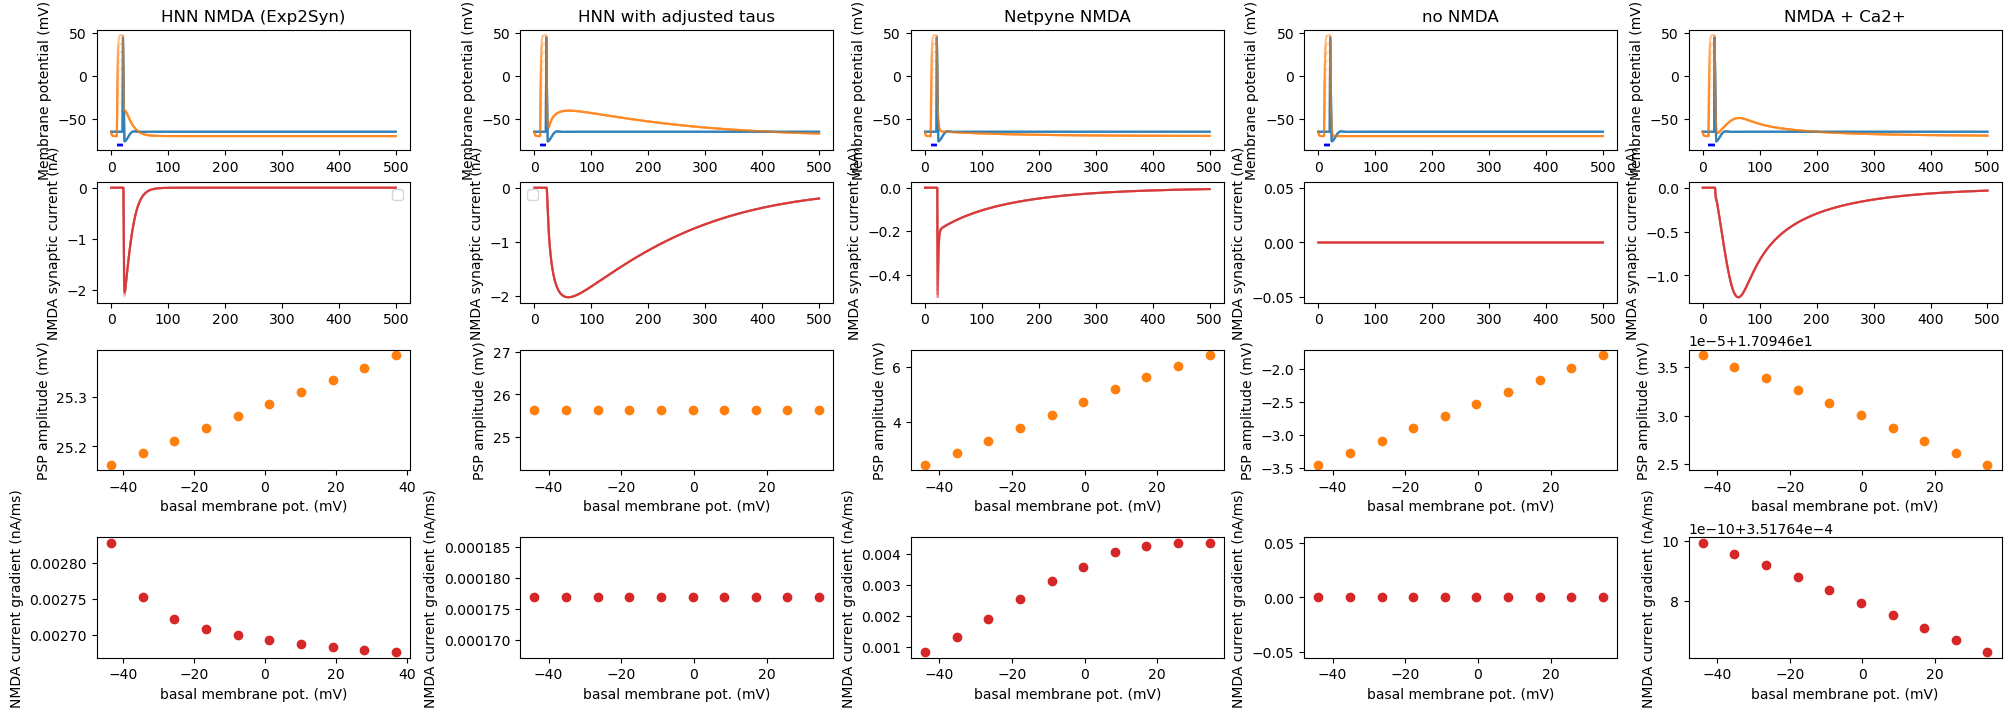

In [8]:
fig, ax = plt.subplots(4, 5, figsize=(20, 7), constrained_layout=True)

bamps = np.linspace(2, 8, 10)
for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 1
    syn.tau2 = 10
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,0].set_title('HNN NMDA (Exp2Syn)')

    ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,0].set_ylabel('Membrane potential (mV)')
    ax[0,0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    t1 = 10
    t2 = 21
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,0].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,0].set_xlabel('basal membrane pot. (mV)')
    ax[2,0].set_ylabel('PSP amplitude (mV)')
 
    ax[1,0].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,0].legend()
    ax[1,0].set_ylabel('NMDA synaptic current (nA)')
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,0].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,0].set_xlabel('basal membrane pot. (mV)')
    ax[3,0].set_ylabel('NMDA current gradient (nA/ms)')
    # ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)

for b, bamp in enumerate(bamps):
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,1].set_title('HNN with adjusted taus')

    ax[0,1].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    ax[0,1].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,1].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,1].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,1].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,1].set_xlabel('basal membrane pot. (mV)')
    ax[2,1].set_ylabel('PSP amplitude (mV)')
 
    ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,1].legend()
    ax[1,1].set_ylabel('NMDA synaptic current (nA)')
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,1].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,1].set_xlabel('basal membrane pot. (mV)')
    ax[3,1].set_ylabel('NMDA current gradient (nA/ms)')

for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,2].set_title('Netpyne NMDA')

    ax[0,2].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,2].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,2].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,2].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,2].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,2].set_xlabel('basal membrane pot. (mV)')
    ax[2,2].set_ylabel('PSP amplitude (mV)')
 
    ax[1,2].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,2].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,2].set_xlabel('basal membrane pot. (mV)')
    ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    # nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    # nc.weight[0] = 0.05
    # nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,3].set_title('no NMDA')

    ax[0,3].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,3].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,3].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,3].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,3].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,3].set_xlabel('basal membrane pot. (mV)')
    ax[2,3].set_ylabel('PSP amplitude (mV)')
 
    ax[1,3].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,3].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,3].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,3].set_xlabel('basal membrane pot. (mV)')
    ax[3,3].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.2
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,4].set_title('NMDA + Ca2+')

    ax[0,4].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)+1-b))
    
    ax[0,4].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)+1-b))
    ax[0,4].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,4].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    print(psp)
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,4].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,4].set_xlabel('basal membrane pot. (mV)')
    ax[2,4].set_ylabel('PSP amplitude (mV)')
 
    ax[1,4].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)+1-b))
    ax[1,4].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,4].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,4].set_xlabel('basal membrane pot. (mV)')
    ax[3,4].set_ylabel('NMDA current gradient (nA/ms)')

fig.savefig(f'{pathfig}/NMDA_comparison_depolarization_long.png')

In [ ]:
psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
psp

np.float64(25.71097672574146)